In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the structured log file
df = pd.read_csv('../data/HDFS_2k.log_structured.csv')

# 1. Look at the data structure
print("--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n--- Column Names ---")
print(df.columns.tolist())

print("\n--- First 3 Rows ---")
display(df.head(3))

# 2. Check the Label Distribution (Normal vs Anomaly)
# Note: The sample file might not have the label column, but let's check.
if 'Label' in df.columns:
    print("\n--- Label Distribution ---")
    print(df['Label'].value_counts())
    
    # Plot it
    sns.countplot(data=df, x='Label')
    plt.title('Distribution of Normal vs Anomaly')
    plt.show()
else:
    print("\nNote: The 'Label' column is not in this sample file. We will add it using the label file.")

--- Dataset Shape ---
Rows: 2000, Columns: 9

--- Column Names ---
['LineId', 'Date', 'Time', 'Pid', 'Level', 'Component', 'Content', 'EventId', 'EventTemplate']

--- First 3 Rows ---


,LineId,Date,Time,Pid,Level,Component,Content,EventId,EventTemplate
0,1,81109,203615,148,INFO,dfs.DataNode$PacketResponder,PacketResponder 1 for block blk_38865049064139...,E10,PacketResponder <*> for block blk_<*> terminating
1,2,81109,203807,222,INFO,dfs.DataNode$PacketResponder,PacketResponder 0 for block blk_-6952295868487...,E10,PacketResponder <*> for block blk_<*> terminating
2,3,81109,204005,35,INFO,dfs.FSNamesystem,BLOCK* NameSystem.addStoredBlock: blockMap upd...,E6,BLOCK* NameSystem.addStoredBlock: blockMap upd...



Note: The 'Label' column is not in this sample file. We will add it using the label file.


/tmp/ipykernel_1662/1754731542.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Level', ax=axes[0], order=df['Level'].value_counts().index, palette='viridis')
/tmp/ipykernel_1662/1754731542.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_components.values, y=top_components.index, ax=axes[1], palette='magma')


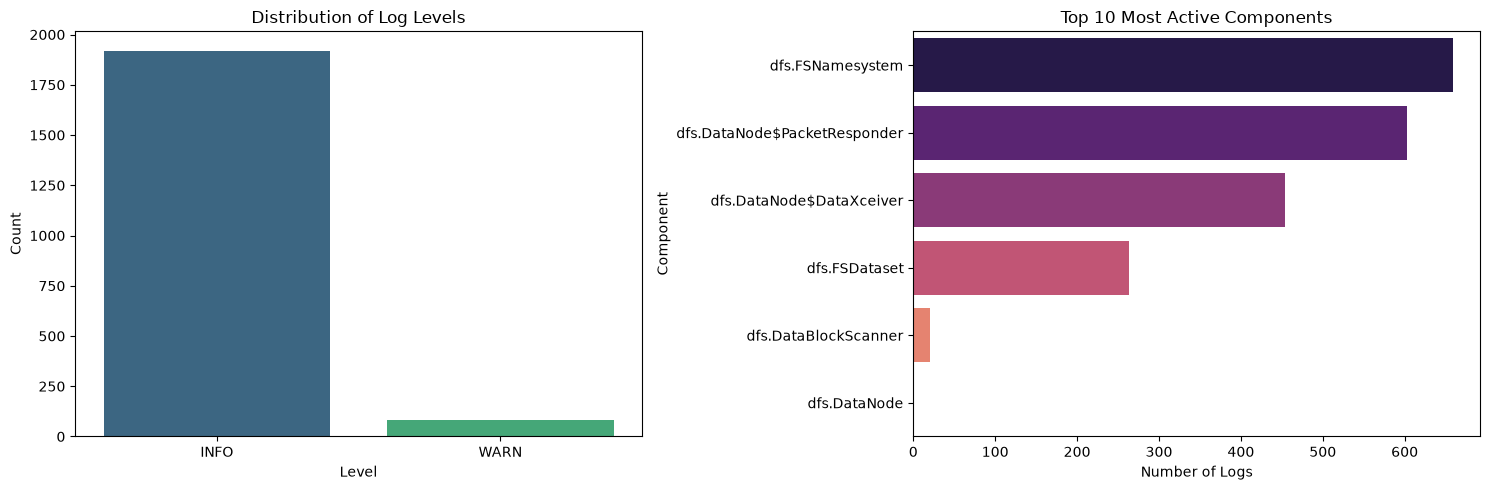

In [2]:
# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. What is the distribution of Log Levels?
sns.countplot(data=df, x='Level', ax=axes[0], order=df['Level'].value_counts().index, palette='viridis')
axes[0].set_title('Distribution of Log Levels')
axes[0].set_ylabel('Count')

# 2. Which Components generate the most logs? (Top 10)
top_components = df['Component'].value_counts().head(10)
sns.barplot(x=top_components.values, y=top_components.index, ax=axes[1], palette='magma')
axes[1].set_title('Top 10 Most Active Components')
axes[1].set_xlabel('Number of Logs')

plt.tight_layout()
plt.show()

In [ ]:
### Data Story: Phase 1 Initial EDA

1. **What the data is:** The dataset consists of 2,000 Hadoop Distributed File System (HDFS) log entries, parsed into 9 columns including severity level, component origin, and generalized event templates.
2. **What surprised me:** While I expected a high volume of errors, the vast majority of logs are `INFO` level, which means anomaly detection cannot simply rely on filtering for `ERROR` logs; the model must learn complex structural patterns.
3. **What I will do about it:** Because the raw `Content` contains unique IDs (like block IDs), I will rely heavily on the `EventTemplate` column to train my models so they can generalize to unseen data.
4. **What I am still unsure of:** I still need to merge this structured data with the ground-truth labels (`abnormal_label.txt`) to understand the class imbalance before training a classifier.